In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


In [2]:
import pandas as pd
sample = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv")
train = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")

# EDA

### Checking for NULL Values in the frame

In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB


### Checking for duplicated values in the frame

In [4]:
train.duplicated().sum()

np.int64(0)

In [5]:
train_copy = train.copy()
answer = train_copy['answer']
opts = []
for idx,ans in enumerate(answer):
    opts.append(train_copy.loc[idx,ans])
opts = pd.Series(opts)
train_copy['correct_option'] = opts

### Checking if there are near repeated questions

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

texts = train_copy["prompt"].tolist()
vectr = TfidfVectorizer(stop_words='english')
vec = vectr.fit_transform(texts)
sim = cosine_similarity(vec)

threshold = 1

pairs = []

for i in range(len(train_copy)):
    for j in range(i+1,(len(train_copy))):
        if sim[i,j]>=threshold:
            pairs.append((i,j,sim[i,j]))
pairs_df = pd.DataFrame(pairs, columns=["row_i", "row_j", "similarity"])
pairs_df

,row_i,row_j,similarity
0,0,1823,1.0
1,3,921,1.0
2,4,499,1.0
3,5,258,1.0
4,8,112,1.0
...,...,...,...
257,1694,1948,1.0
258,1697,1746,1.0
259,1739,1869,1.0
260,1804,1818,1.0


## Label Distribution

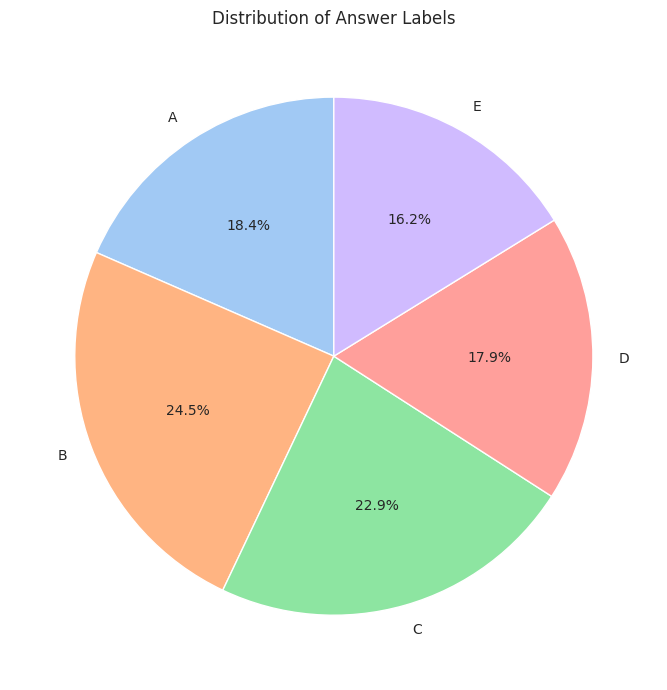

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

answer_counts = train["answer"].value_counts().sort_index()
sns.set_style("whitegrid")
colors = sns.color_palette("pastel", len(answer_counts))

plt.figure(figsize=(7, 7))
plt.pie(
    answer_counts,
    labels=answer_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
)

plt.title("Distribution of Answer Labels")
plt.tight_layout()
plt.show()

# Model Building
# 1) Finetuning a Pretrained Transformer (DeBERTa)

In [8]:
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForMultipleChoice, get_linear_schedule_with_warmup
from torch.optim import AdamW

## Config

In [11]:
MODEL_NAME  = "microsoft/deberta-v3-small"
MAX_LEN     = 256
BATCH_SIZE  = 8      
EPOCHS      = 3
LR          = 2e-5
LABEL_MAP   = {'A':0,'B':1,'C':2,'D':3,'E':4}
INV_LABEL_MAP = {0 :'A',1:'B',2:'C',3:'D',4:'E'}
DEVICE      = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Dataset

In [12]:
class MCQDataset(Dataset):
    def __init__(self, df, tokenizer, max_len):
        self.df        = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row     = self.df.iloc[idx]
        prompt  = row['prompt']
        options = [row['A'], row['B'], row['C'], row['D'], row['E']]
        label   = LABEL_MAP[row['answer']]
        
        encodings = [
            self.tokenizer(prompt, opt, truncation=True,
                           max_length=self.max_len, padding="max_length",
                           return_tensors="pt")
            for opt in options
        ]
        input_ids      = torch.stack([e["input_ids"].squeeze()      for e in encodings])  
        attention_mask = torch.stack([e["attention_mask"].squeeze() for e in encodings])
        
        return {
            "input_ids":      input_ids,
            "attention_mask": attention_mask,
            "labels":         torch.tensor(label, dtype=torch.long)
        }


In [13]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model     = AutoModelForMultipleChoice.from_pretrained(MODEL_NAME,torch_dtype=torch.float32).to(DEVICE)

dataset   = MCQDataset(train, tokenizer, MAX_LEN)
loader    = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=len(loader),          
    num_training_steps=len(loader) * EPOCHS
)

config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


pytorch_model.bin:   0%|          | 0.00/286M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

DebertaV2ForMultipleChoice LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.dense.bias               

model.safetensors:   0%|          | 0.00/286M [00:00<?, ?B/s]

## Training

In [22]:
# from torch.cuda.amp import autocast, GradScaler
# scaler = GradScaler()

for epoch in range(EPOCHS):
    model.train()
    total_loss, correct = 0, 0

    for batch in loader:
        optimizer.zero_grad()
        input_ids      = batch["input_ids"].to(DEVICE)       
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels         = batch["labels"].to(DEVICE)          

        outputs = model(input_ids=input_ids,
                        attention_mask=attention_mask,
                        labels=labels)   

        loss = outputs.loss              
        loss.backward()                 
        optimizer.step()              
        scheduler.step()
        

        total_loss += loss.item()
        preds = outputs.logits.argmax(dim=-1)
        correct += (preds == labels).sum().item()

    acc = correct / len(train)
    print(f"Epoch {epoch+1} | Loss: {total_loss/len(loader):.4f} | Top-1 Acc: {acc:.4f}")

Epoch 1 | Loss: 1.5199 | Top-1 Acc: 0.3025
Epoch 2 | Loss: 0.5766 | Top-1 Acc: 0.7860
Epoch 3 | Loss: 0.2787 | Top-1 Acc: 0.8950


## Testing with one training sample

In [25]:
model.to('cuda')
model.eval()
with torch.no_grad():
    sample   = dataset[246]
    ids      = sample["input_ids"].unsqueeze(0).to(DEVICE)
    attn     = sample["attention_mask"].unsqueeze(0).to(DEVICE)
    logits   = model(input_ids=ids, attention_mask=attn).logits
    probs    = F.softmax(logits, dim=-1)
    top3_p, top3_i = torch.topk(probs, k=3, dim=-1)
    options  = ['A','B','C','D','E']
    print("Top-3 guesses:", [options[i] for i in top3_i[0].tolist()])
    print("Confidences:  ", top3_p[0].tolist())
    print(f"Actual Answer: {INV_LABEL_MAP[sample['labels'].item()]}")

Top-3 guesses: ['D', 'A', 'C']
Confidences:   [0.9991105198860168, 0.00045120209688320756, 0.00018972410180140287]
Actual Answer: D


## Appying on the test dataset

In [26]:
MAX_LEN  = 256       
BATCH_SZ = 8
TOP_N    = 3
LABEL_MAP_INV = {0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'E'}

class MCQTestDataset(Dataset):
    def __init__(self, df, tokenizer, max_len):
        self.df        = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row     = self.df.iloc[idx]
        prompt  = row['prompt']
        options = [row['A'], row['B'], row['C'], row['D'], row['E']]

        encodings = [
            self.tokenizer(prompt, opt,
                           truncation=True,
                           max_length=self.max_len,
                           padding="max_length",
                           return_tensors="pt")
            for opt in options
        ]

        input_ids      = torch.stack([e["input_ids"].squeeze()      for e in encodings])
        attention_mask = torch.stack([e["attention_mask"].squeeze() for e in encodings]) 

        return {
            "input_ids":      input_ids,
            "attention_mask": attention_mask,
            "id":             row["id"],
        }

test_dataset = MCQTestDataset(test, tokenizer, MAX_LEN)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SZ, shuffle=False)

In [27]:
model.eval()

all_ids         = []
all_top_n_labels = []
all_top_n_probs  = []

with torch.no_grad():
    for batch in test_loader:
        input_ids      = batch["input_ids"].to(DEVICE)      
        attention_mask = batch["attention_mask"].to(DEVICE) 
        ids            = batch["id"].tolist()               

        outputs = model(input_ids=input_ids,
                        attention_mask=attention_mask)      
        probs   = F.softmax(outputs.logits, dim=-1)        

        top_probs, top_idx = torch.topk(probs, k=3, dim=-1)  

        for i, qid in enumerate(ids):
            labels_i = [LABEL_MAP_INV[j.item()] for j in top_idx[i]]
            probs_i  = [round(p.item(), 4) for p in top_probs[i]]

            all_ids.append(qid)
            all_top_n_labels.append(labels_i)
            all_top_n_probs.append(probs_i)

In [28]:
submission = pd.DataFrame({
    "ID":        all_ids,
    "Prediction": [" ".join(labels) for labels in all_top_n_labels],  
})
submission.to_csv("submission.csv", index=False)
print(submission.head())

   ID Prediction
0   1      A B C
1   2      B D C
2   3      B E D
3   4      E C D
4   5      C A D


In [ ]:
# sample1 = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv")
# sample1

In [29]:
import os
save_dir = "/kaggle/working/mcq_deberta_model"
os.makedirs(save_dir, exist_ok=True)

model.to("cpu")
model.save_pretrained(save_dir)
tokenizer.save_pretrained(save_dir)

print("Saved model to:", save_dir)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model to: /kaggle/working/mcq_deberta_model


# 2) Custom built Transformer Encoder

In [3]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer

## Config

In [4]:
TOKENIZER_NAME = "bert-base-uncased"
MAX_LEN    = 128
D_MODEL    = 256
N_HEADS    = 8
N_LAYERS   = 4
FFN_DIM    = 512
DROPOUT    = 0.1
BATCH_SIZE = 16
EPOCHS     = 5
LR         = 3e-4
TOP_N      = 3
CHOICES    = ["A", "B", "C", "D", "E"]
LABEL_MAP  = {c: i for i, c in enumerate(CHOICES)}
INV_LABEL  = {i: c for c, i in LABEL_MAP.items()}
DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

## Dataset

In [5]:
class MCQDataset(Dataset):
    def __init__(self, df, has_labels=True):
        self.df = df.reset_index(drop=True)
        self.has_labels = has_labels

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        prompt = str(row["prompt"])

        all_ids, all_masks = [], []
        for choice in CHOICES:
            enc = tokenizer(
                prompt,
                str(row[choice]),
                truncation=True,
                padding="max_length",
                max_length=MAX_LEN,
                return_tensors="pt"
            )
            all_ids.append(enc["input_ids"].squeeze())
            all_masks.append(enc["attention_mask"].squeeze())

        item = {
            "input_ids": torch.stack(all_ids),       
            "attention_mask": torch.stack(all_masks), 
        }

        if self.has_labels:
            item["label"] = torch.tensor(LABEL_MAP[row["answer"]])

        return item

In [6]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

In [7]:
class TransformerMCQ(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(
            tokenizer.vocab_size, D_MODEL,
            padding_idx=tokenizer.pad_token_id
        )
        self.pos_enc = PositionalEncoding(D_MODEL)
        self.dropout = nn.Dropout(DROPOUT)

        layer = nn.TransformerEncoderLayer(
            d_model=D_MODEL, nhead=N_HEADS,
            dim_feedforward=FFN_DIM, dropout=DROPOUT,
            activation="gelu", batch_first=True, norm_first=True
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=N_LAYERS)
        self.fc = nn.Linear(D_MODEL, 1)

    def encode(self, input_ids, attention_mask):
        pad_mask = (attention_mask == 0)
        x = self.dropout(self.pos_enc(self.embedding(input_ids)))
        x = self.encoder(x, src_key_padding_mask=pad_mask)
        return self.dropout(x[:, 0, :])

    def forward(self, input_ids, attention_mask):
        B, N, L = input_ids.shape
        ids   = input_ids.view(B * N, L)
        masks = attention_mask.view(B * N, L)
        out   = self.fc(self.encode(ids, masks))
        return out.view(B, N)

In [8]:
def get_accuracy(logits, labels, k=1):
    top_preds = torch.topk(logits,k=k).indices
    labels = labels.view(-1,1)
    correct = (top_preds == labels).any(dim=1)
    accuracy = correct.float().mean()
    return accuracy.item()

# def map3(logits, labels):
#     top_preds = torch.topk(logits,k=TOP_N).indices
#     indices = top_preds.squeeze(0).tolist()  

def run_epoch(model, loader, criterion, optimizer=None):
    if optimizer:
        istrain = True
    else:
        istrain = False
    
    model.train() if istrain else model.eval()

    total_loss, n = 0, 0
    all_logits, all_labels = [], []

    if istrain:
        ctx = torch.enable_grad()
    else:
        ctx = torch.no_grad()
    
    with ctx:
        for batch in loader:
            ids    = batch["input_ids"].to(DEVICE)
            masks  = batch["attention_mask"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            logits = model(ids, masks)
            loss   = criterion(logits, labels)

            if istrain:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            n += labels.size(0)
            all_logits.append(logits.detach().cpu())
            all_labels.append(labels.cpu())

    logits = torch.cat(all_logits)
    labels = torch.cat(all_labels)

    return total_loss / n, get_accuracy(logits, labels, TOP_N)

In [9]:
tr_df, val_df = train_test_split(
    train, test_size=0.2, random_state=42, stratify=train["answer"]
)

train_dataset = MCQDataset(tr_df)
val_dataset = MCQDataset(val_df)
test_dataset = MCQDataset(test, has_labels = False)

train_loader = DataLoader(train_dataset,batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset,batch_size=BATCH_SIZE)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE)

model     = TransformerMCQ().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=LR, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

print(f"Params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

/tmp/ipykernel_59/762310506.py:16: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(layer, num_layers=N_LAYERS)


Params: 9,922,305


## Setting up WandB

In [11]:
import wandb
from kaggle_secrets import UserSecretsClient

# Fetch the secret API key from Kaggle
user_secrets = UserSecretsClient()
wandb_api_key = user_secrets.get_secret("WANDB_API_KEY")

# Authenticate with Weights & Biases
wandb.login(key=wandb_api_key)

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

In [12]:
import wandb

run = wandb.init(
    # Set the wandb entity where your project will be logged (generally your team name).
    entity="ayan-ansari7437-indian-institute-of-technology-madras",
    # Set the wandb project where this run will be logged.
    project="23f3001359-t22026",
    # Track hyperparameters and run metadata.
    config={
        "learning_rate": 0.0003,
        "architecture": "Transformer Encoder",
        "dataset": "Training",
        "epochs": 5,
    },
)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_accN = run_epoch(model, train_loader, criterion, optimizer)
    va_loss, va_accN = run_epoch(model, val_loader,   criterion)
    scheduler.step()

    print(f"Epoch {epoch:02d} | Training: Loss = {tr_loss:.4f} Accuracy = {tr_accN:.4f}"
          f" | Validation: Loss = {va_loss:.4f} Accuracy = {va_accN:.4f}")
    run.log({"acc": tr_accN, "loss": tr_loss})

run.finish()

Epoch 01 | Training: Loss = 1.3686 Accuracy = 0.7887 | Validation: Loss = 0.8744 Accuracy = 0.9500
Epoch 02 | Training: Loss = 0.9165 Accuracy = 0.9062 | Validation: Loss = 0.4550 Accuracy = 0.9675
Epoch 03 | Training: Loss = 0.5648 Accuracy = 0.9688 | Validation: Loss = 0.2864 Accuracy = 0.9875
Epoch 04 | Training: Loss = 0.4067 Accuracy = 0.9775 | Validation: Loss = 0.1813 Accuracy = 0.9900
Epoch 05 | Training: Loss = 0.3319 Accuracy = 0.9831 | Validation: Loss = 0.1568 Accuracy = 0.9900


acc,▁▅▇██
loss,█▅▃▂▁
acc,0.98312
loss,0.33188


## Testing on one training sample

In [13]:
model.eval()
with torch.no_grad():
    sample_test = train_dataset[1111]
    sample_test_inputids = sample_test["input_ids"].unsqueeze(0).to(DEVICE)
    sample_test_attention = sample_test["attention_mask"].unsqueeze(0).to(DEVICE)
    logits = model(sample_test_inputids,sample_test_attention)
    prob = F.softmax(logits,dim=-1)
    top_indices = torch.topk(prob,k=3).indices
    top_indices = top_indices.squeeze(0).tolist()
    top_guess = [INV_LABEL[index] for index in top_indices]
    print(f"Top 3 guesses : {top_guess}")
    print(f"Actual answer: {INV_LABEL[sample_test["label"].item()]}")

Top 3 guesses : ['C', 'E', 'A']
Actual answer: C


## Inferencing on the test dataset

In [15]:
def predict(model, loader):
    model.eval()
    all_labels, all_probs = [], []

    with torch.no_grad():
        for batch in loader:
            ids   = batch["input_ids"].to(DEVICE)
            masks = batch["attention_mask"].to(DEVICE)
            logits = model(ids, masks)
            probs = F.softmax(logits, dim=-1)
            top_p, top_i = torch.topk(probs, TOP_N, dim=-1)

            for i in range(ids.size(0)):
                all_labels.append([INV_LABEL[j.item()] for j in top_i[i]])
                all_probs.append([round(p.item(), 4) for p in top_p[i]])

    return all_labels, all_probs

In [16]:
labels, probs = predict(model,test_loader)
prediction = [" ".join(label) for label in labels]
ids = [i for i in range(1,len(prediction)+1)]
submission = pd.DataFrame({"ID":ids,"Prediction":prediction})
submission.to_csv('submission.csv',index=False)

In [17]:
submission.head()

,ID,Prediction
0,1,A E B
1,2,B E C
2,3,B D E
3,4,E D A
4,5,C A D


# 3)RAG Based System

In [ ]:
!pip install faiss-cpu
import pandas as pd
import numpy as np
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel, AutoModelForMultipleChoice
import faiss

MODEL_NAME = "roberta-large"
device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()

OPTION_COLS = ["A", "B", "C", "D", "E"]

## Creating the embedding Index

In [ ]:
def embed(texts,batch_size=16):
    vecs=[]
    for i in range(0,len(texts),batch_size):
        batch = texts[i:i+16]
        enc = tokenizer(batch, truncation=True, padding=True,
                       max_length=128, return_tensors='pt').to(device)
        with torch.no_grad():
            out = model(**enc)
        mask = enc["attention_mask"].unsqueeze(-1)
        pooled = (out.last_hidden_state * mask).sum(1) / mask.sum(1).clamp(min=1e-9)
        pooled = F.normalize(pooled, p=2, dim=1)
        vecs.append(pooled.cpu().numpy())
    return np.vstack(vecs)

docs = (train["prompt"]+" "+train[OPTION_COLS].agg(" ".join, axis=1)).tolist()
doc_embeddings = embed(docs)

index = faiss.IndexFlatIP(doc_embeddings.shape[1])
index.add(doc_embeddings.astype("float32"))

def retrieve(query, k=5):
    q_emb = embed([query])
    scores, idxs = index.search(q_emb.astype("float32"), k)
    return train.iloc[idxs[0]]

def resolve_answer_text(row):
    letter = row["answer"]
    return row[letter]

def rank_by_similarity(prompt,options,top_k=3):
    context = retrieve(prompt,k=5)
    seen_answers = set(context.apply(resolve_answer_text,axis=1).str.lower())
    q_emb = embed([prompt])[0]
    scored = []
    for letter,text in options.items():
        opt_emb = embed([prompt+" "+text])[0]
        sim = float(np.dot(opt_emb,q_emb))
        if text.lower() in seen_answers:
            sim += 0.15
        scored.append((letter,text,sim))
    scored.sort(key=lambda x: x[2],reverse=True)
    return scored[:top_k],context

## Testing on one sample

In [ ]:
row = train.iloc[122]
prompt = row["prompt"]
options = {letter: row[letter] for letter in OPTION_COLS}

top_3, context = rank_by_similarity(prompt, options, top_k=3)

print(context)
print(top_3)

In [ ]:
def predict_top3(row):
    prompt = row['prompt']
    options = {letter: row[letter] for letter in OPTION_COLS}
    top_3 , context = rank_by_similarity(prompt,options,3)
    letters = [letter for letter,text,sim in top_3]
    top3_string = " ".join(letters)
    return top3_string

In [ ]:
predict_top3(train.iloc[122])

In [ ]:
row_ids = []
predictions = []

for idx,row in test.iterrows():
    row_ids.append(idx+1)
    row_preds = predict_top3(row)
    predictions.append(row_preds)

In [ ]:
submission = pd.DataFrame({'ID':row_ids,'Prediction':predictions})

In [ ]:
submission.to_csv("submission.csv", index=False)